# Data cleaning and analysis

## Data cleaning - poa

- Remove useless columns
- Remove model of car and just leave brand in name category
- Change transmission to 1 (Manual) and 0 (Automatic) 
- Change fuel type to 1 (Diesel) and 0 (Petrol), decide what to do with other
- Convert all mileage into km/L
- Remove CC from Engine type and change type to int64
- Remove bhp from Power and change to float64
- Look for NaN or null values and decide what to do

In [381]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

In [382]:
df = pd.read_csv('used_cars_data-selected-columns.csv')
df.head()

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,17.74


In [383]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No.              7253 non-null   int64  
 1   Name               7253 non-null   str    
 2   Location           7253 non-null   str    
 3   Year               7253 non-null   int64  
 4   Kilometers_Driven  7253 non-null   int64  
 5   Fuel_Type          7253 non-null   str    
 6   Transmission       7253 non-null   str    
 7   Owner_Type         7253 non-null   str    
 8   Mileage            7251 non-null   str    
 9   Engine             7207 non-null   str    
 10  Power              7207 non-null   str    
 11  Price              6019 non-null   float64
dtypes: float64(1), int64(3), str(8)
memory usage: 680.1 KB


In [384]:
df.describe()

,S.No.,Year,Kilometers_Driven,Price
count,7253.000000,7253.000000,7.253000e+03,6019.000000
mean,3626.000000,2013.365366,5.869906e+04,9.479468
std,2093.905084,3.254421,8.442772e+04,11.187917
min,0.000000,1996.000000,1.710000e+02,0.440000
25%,1813.000000,2011.000000,3.400000e+04,3.500000
50%,3626.000000,2014.000000,5.341600e+04,5.640000
75%,5439.000000,2016.000000,7.300000e+04,9.950000
max,7252.000000,2019.000000,6.500000e+06,160.000000


In [385]:
df.isnull().sum()

S.No.                   0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 46
Power                  46
Price                1234
dtype: int64

In [386]:
df.shape

(7253, 12)

# Key observations

- Quite a few of the numerical values have data types of strings due to units after the numbers. These will need to be removed and the data type changed
- Price has 1234 values as null. This is hard to just take the overall average due to a varity of brands. My plan is to find the brand average and fill them in for the avearge fromt that brand.
- Price is in a currency of Lakh as this dataset is indian based. It is in base units of 100,000 so the exchage rate is about £825 to 1. This is as accurate conversion as I can find.
- The missing values in Engine, Power and Milage will just be removed for ease.

In [387]:
df.drop('Owner_Type', axis='columns', inplace=True)
df.head()

C:\Users\hillt\AppData\Local\Temp\ipykernel_35232\3141281988.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('Owner_Type', axis='columns', inplace=True)


,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Mileage,Engine,Power,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,26.6 km/kg,998 CC,58.16 bhp,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,19.67 kmpl,1582 CC,126.2 bhp,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,18.2 kmpl,1199 CC,88.7 bhp,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,20.77 kmpl,1248 CC,88.76 bhp,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,15.2 kmpl,1968 CC,140.8 bhp,17.74


In [388]:
df.drop('Location', axis='columns', inplace=True)
df.head()

C:\Users\hillt\AppData\Local\Temp\ipykernel_35232\3263970753.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('Location', axis='columns', inplace=True)


,S.No.,Name,Year,Kilometers_Driven,Fuel_Type,Transmission,Mileage,Engine,Power,Price
0,0,Maruti Wagon R LXI CNG,2010,72000,CNG,Manual,26.6 km/kg,998 CC,58.16 bhp,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,2015,41000,Diesel,Manual,19.67 kmpl,1582 CC,126.2 bhp,12.50
2,2,Honda Jazz V,2011,46000,Petrol,Manual,18.2 kmpl,1199 CC,88.7 bhp,4.50
3,3,Maruti Ertiga VDI,2012,87000,Diesel,Manual,20.77 kmpl,1248 CC,88.76 bhp,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,2013,40670,Diesel,Automatic,15.2 kmpl,1968 CC,140.8 bhp,17.74


In [389]:
df['Power'] = df['Power'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df['Power'] = pd.to_numeric(df['Power'], errors='coerce').astype('float64')
df.head()

,S.No.,Name,Year,Kilometers_Driven,Fuel_Type,Transmission,Mileage,Engine,Power,Price
0,0,Maruti Wagon R LXI CNG,2010,72000,CNG,Manual,26.6 km/kg,998 CC,58.16,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,2015,41000,Diesel,Manual,19.67 kmpl,1582 CC,126.20,12.50
2,2,Honda Jazz V,2011,46000,Petrol,Manual,18.2 kmpl,1199 CC,88.70,4.50
3,3,Maruti Ertiga VDI,2012,87000,Diesel,Manual,20.77 kmpl,1248 CC,88.76,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,2013,40670,Diesel,Automatic,15.2 kmpl,1968 CC,140.80,17.74


In [390]:
df['Engine'] = df['Engine'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df['Engine'] = pd.to_numeric(df['Engine'], errors='coerce').astype('Int64')
df.head()

,S.No.,Name,Year,Kilometers_Driven,Fuel_Type,Transmission,Mileage,Engine,Power,Price
0,0,Maruti Wagon R LXI CNG,2010,72000,CNG,Manual,26.6 km/kg,998,58.16,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,2015,41000,Diesel,Manual,19.67 kmpl,1582,126.20,12.50
2,2,Honda Jazz V,2011,46000,Petrol,Manual,18.2 kmpl,1199,88.70,4.50
3,3,Maruti Ertiga VDI,2012,87000,Diesel,Manual,20.77 kmpl,1248,88.76,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,2013,40670,Diesel,Automatic,15.2 kmpl,1968,140.80,17.74


In [391]:
milage_in_km_kg_mask = (df['Mileage'].str.contains('km/kg'))
milage_in_km_kg_filter = df[milage_in_km_kg_mask]
milage_in_km_kg_filter

,S.No.,Name,Year,Kilometers_Driven,Fuel_Type,Transmission,Mileage,Engine,Power,Price
0,0,Maruti Wagon R LXI CNG,2010,72000,CNG,Manual,26.6 km/kg,998,58.16,1.75
5,5,Hyundai EON LPG Era Plus Option,2012,75000,LPG,Manual,21.1 km/kg,814,55.20,2.35
127,127,Maruti Wagon R LXI CNG,2013,89900,CNG,Manual,26.6 km/kg,998,58.16,3.25
328,328,Maruti Zen Estilo LXI Green (CNG),2008,42496,CNG,Manual,26.3 km/kg,998,67.10,1.40
440,440,Maruti Eeco 5 STR With AC Plus HTR CNG,2017,31841,CNG,Manual,15.1 km/kg,1196,73.00,4.70
...,...,...,...,...,...,...,...,...,...,...
6538,6538,Maruti Alto K10 LXI CNG,2015,47490,CNG,Manual,32.26 km/kg,998,58.20,NaN
6788,6788,Maruti Alto K10 LXI CNG Optional,2017,33000,CNG,Manual,32.26 km/kg,998,58.20,NaN
6918,6918,Hyundai Accent Executive LPG,2010,40000,LPG,Manual,13.2 km/kg,1495,93.70,NaN
6926,6926,Maruti Eeco 5 STR With AC Plus HTR CNG,2017,15500,CNG,Manual,15.1 km/kg,1196,73.00,NaN


In [392]:
df['Mileage'] = df['Mileage'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df['Mileage'] = pd.to_numeric(df['Mileage'], errors='coerce').astype('float64')
df.head()

,S.No.,Name,Year,Kilometers_Driven,Fuel_Type,Transmission,Mileage,Engine,Power,Price
0,0,Maruti Wagon R LXI CNG,2010,72000,CNG,Manual,26.60,998,58.16,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,2015,41000,Diesel,Manual,19.67,1582,126.20,12.50
2,2,Honda Jazz V,2011,46000,Petrol,Manual,18.20,1199,88.70,4.50
3,3,Maruti Ertiga VDI,2012,87000,Diesel,Manual,20.77,1248,88.76,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,2013,40670,Diesel,Automatic,15.20,1968,140.80,17.74


In [393]:
df.loc[milage_in_km_kg_filter.index, 'Mileage'] = df.loc[milage_in_km_kg_filter.index, 'Mileage'] * 0.79

In [394]:
df['Brand'] = df['Name'].str.split(n=1).str[0]

In [395]:
df.head()

,S.No.,Name,Year,Kilometers_Driven,Fuel_Type,Transmission,Mileage,Engine,Power,Price,Brand
0,0,Maruti Wagon R LXI CNG,2010,72000,CNG,Manual,21.014,998,58.16,1.75,Maruti
1,1,Hyundai Creta 1.6 CRDi SX Option,2015,41000,Diesel,Manual,19.670,1582,126.20,12.50,Hyundai
2,2,Honda Jazz V,2011,46000,Petrol,Manual,18.200,1199,88.70,4.50,Honda
3,3,Maruti Ertiga VDI,2012,87000,Diesel,Manual,20.770,1248,88.76,6.00,Maruti
4,4,Audi A4 New 2.0 TDI Multitronic,2013,40670,Diesel,Automatic,15.200,1968,140.80,17.74,Audi


In [396]:
df = df.drop(columns='Name')

In [397]:
df['Transmission'] = df['Transmission'].map({'Manual': 1, 'Automatic': 0})
df.head()

,S.No.,Year,Kilometers_Driven,Fuel_Type,Transmission,Mileage,Engine,Power,Price,Brand
0,0,2010,72000,CNG,1,21.014,998,58.16,1.75,Maruti
1,1,2015,41000,Diesel,1,19.670,1582,126.20,12.50,Hyundai
2,2,2011,46000,Petrol,1,18.200,1199,88.70,4.50,Honda
3,3,2012,87000,Diesel,1,20.770,1248,88.76,6.00,Maruti
4,4,2013,40670,Diesel,0,15.200,1968,140.80,17.74,Audi


In [398]:
df['Fuel_Type'].value_counts()

Fuel_Type
Diesel      3852
Petrol      3325
CNG           62
LPG           12
Electric       2
Name: count, dtype: int64

In [399]:
df = df[df['Fuel_Type'].isin(['Diesel', 'Petrol'])]

In [400]:
df['Fuel_Type'].value_counts()

Fuel_Type
Diesel    3852
Petrol    3325
Name: count, dtype: int64

In [401]:
df['Fuel_Type'] = df['Fuel_Type'].map({'Diesel': 1, 'Petrol': 0})

In [402]:
df = df.dropna(subset=['Engine'])

In [403]:
df.isnull().sum()

S.No.                   0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Mileage                 0
Engine                  0
Power                 128
Price                1216
Brand                   0
dtype: int64

In [404]:
df = df.dropna(subset=['Power'])

In [405]:
df.isnull().sum()

S.No.                   0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Mileage                 0
Engine                  0
Power                   0
Price                1194
Brand                   0
dtype: int64

In [406]:
df.shape

(7003, 10)

In [407]:
df.groupby('Brand')['Price'].mean()

Brand
Ambassador         1.350000
Audi              25.569787
BMW               25.439618
Bentley           59.000000
Chevrolet          3.057333
Datsun             3.049231
Fiat               3.570435
Force              9.333333
Ford               6.946339
Honda              5.417970
Hyundai            5.531914
ISUZU             12.045000
Isuzu             20.000000
Jaguar            37.632250
Jeep              18.718667
Lamborghini      120.000000
Land-Rover        39.861053
Mahindra           8.058955
Maruti             4.608573
Mercedes-Benz     26.917848
Mini              26.896923
Mitsubishi        11.058889
Nissan             4.784719
OpelCorsa               NaN
Porsche           49.204375
Renault            5.799034
Skoda              7.586453
Tata               3.609503
Toyota            11.929746
Volkswagen         5.306815
Volvo             18.802857
Name: Price, dtype: float64

In [408]:
df = df[df['Brand'] != 'OpelCorsa']

In [409]:
df.groupby('Brand')['Price'].mean()

Brand
Ambassador         1.350000
Audi              25.569787
BMW               25.439618
Bentley           59.000000
Chevrolet          3.057333
Datsun             3.049231
Fiat               3.570435
Force              9.333333
Ford               6.946339
Honda              5.417970
Hyundai            5.531914
ISUZU             12.045000
Isuzu             20.000000
Jaguar            37.632250
Jeep              18.718667
Lamborghini      120.000000
Land-Rover        39.861053
Mahindra           8.058955
Maruti             4.608573
Mercedes-Benz     26.917848
Mini              26.896923
Mitsubishi        11.058889
Nissan             4.784719
Porsche           49.204375
Renault            5.799034
Skoda              7.586453
Tata               3.609503
Toyota            11.929746
Volkswagen         5.306815
Volvo             18.802857
Name: Price, dtype: float64

In [410]:
df.groupby('Brand')['Price'].apply(lambda x: x.isnull().sum())

Brand
Ambassador         0
Audi              49
BMW               43
Bentley            1
Chevrolet         30
Datsun             4
Fiat               9
Force              0
Ford              48
Honda            135
Hyundai          224
ISUZU              1
Isuzu              1
Jaguar             8
Jeep               4
Lamborghini        0
Land-Rover         7
Mahindra          58
Maruti           223
Mercedes-Benz     62
Mini               5
Mitsubishi         9
Nissan            24
Porsche            1
Renault           25
Skoda             28
Tata              41
Toyota            87
Volkswagen        59
Volvo              7
Name: Price, dtype: int64

In [411]:
df.loc[df['Brand'] == 'Honda', 'Price'] = df.loc[df['Brand'] == 'Honda', 'Price'].fillna(5.42)

In [412]:
df.loc[df['Brand'] == 'Hyundai', 'Price'] = df.loc[df['Brand'] == 'Hyundai', 'Price'].fillna(5.53)

In [413]:
df.loc[df['Brand'] == 'Maruti', 'Price'] = df.loc[df['Brand'] == 'Maruti', 'Price'].fillna(4.61)

In [414]:
df.loc[df['Brand'] == 'Mercedes-Benz', 'Price'] = df.loc[df['Brand'] == 'Mercedes-Benz', 'Price'].fillna(26.9)

# Data Analysis - poa

- Looking at type of engine and power on a line graph seeing the relationship
- Looking at price vs power overall for all cars then looking at two specific brands
- A bar chart to see how fuel type effects the milage of the car. Comparing Disel = 1 and Petrol = 0 to the milage
- Looking at the years vs transmission (manual = 1 and automatic = 0) potentially using a histogram. also a pie chart to see the amount of manual compared to automatic
- Comparing the price of brands and then looking at two individual brands to see the variety of prices. bar and scatter for these two


In [415]:
engine_type = df.sort_values(by=['Engine'])
engine_type

,S.No.,Year,Kilometers_Driven,Fuel_Type,Transmission,Mileage,Engine,Power,Price,Brand
41,41,2014,19698,0,1,25.40,624,37.50,1.53,Tata
7194,7194,2016,53590,0,0,21.90,624,37.48,NaN,Tata
6774,6774,2013,35000,0,1,25.40,624,37.48,NaN,Tata
4561,4561,2014,42083,0,1,25.40,624,37.48,1.68,Tata
112,112,2014,25500,0,1,25.40,624,37.50,2.15,Tata
...,...,...,...,...,...,...,...,...,...,...
152,152,2010,35277,0,0,7.81,5461,362.90,30.00,Mercedes-Benz
4722,4722,2010,35000,0,0,8.10,5461,387.30,29.50,Mercedes-Benz
4691,4691,2014,3000,0,0,12.00,5461,421.00,90.00,Mercedes-Benz
6354,6354,2008,31200,0,0,10.20,5998,616.00,NaN,Bentley


Text(0, 0.5, 'Power')

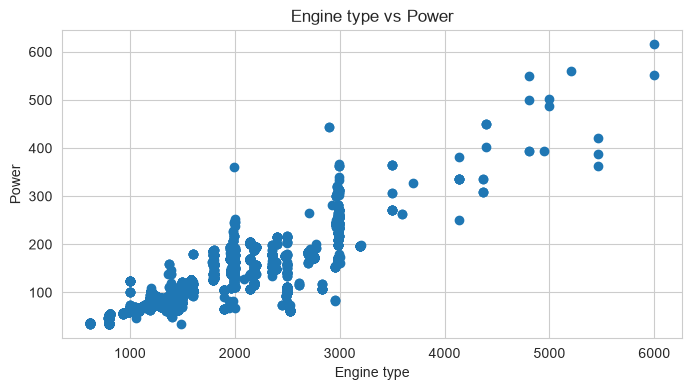

In [416]:
plt.figure(figsize=(8, 4))
plt.scatter(engine_type['Engine'], engine_type['Power'])
plt.title('Engine type vs Power')
plt.xlabel('Engine type')
plt.ylabel('Power')

<Axes: xlabel='Engine', ylabel='Power'>

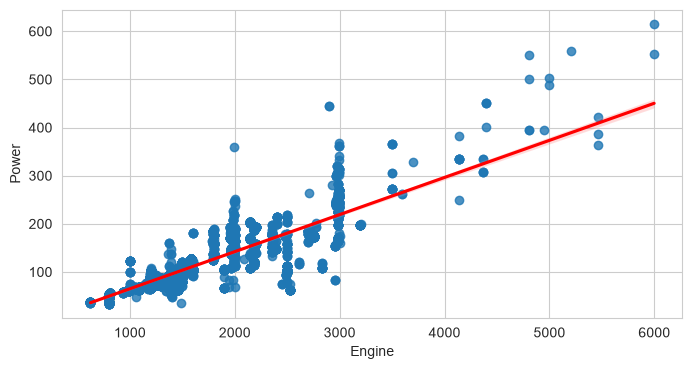

In [417]:
plt.figure(figsize=(8, 4))
sns.regplot(data=df, x='Engine', y='Power', line_kws={'color': 'red'})

Text(0, 0.5, 'Price')

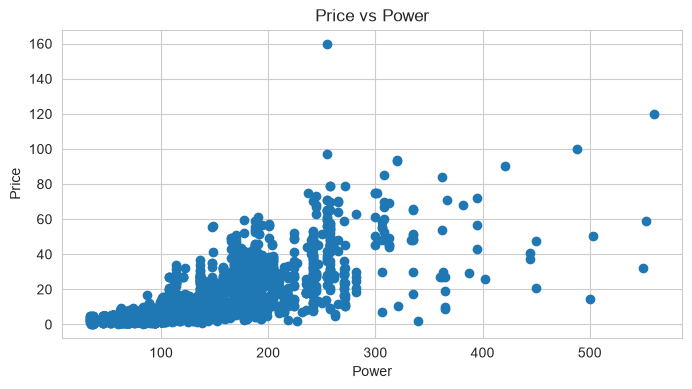

In [418]:
plt.figure(figsize=(8, 4))
plt.scatter(df['Power'], df['Price'])
plt.title('Price vs Power')
plt.xlabel('Power')
plt.ylabel('Price')

In [419]:
df['Brand'].value_counts()

Brand
Maruti           1344
Hyundai          1274
Honda             736
Toyota            480
Mercedes-Benz     378
Volkswagen        373
Ford              343
Mahindra          326
BMW               305
Audi              284
Tata              222
Skoda             200
Renault           170
Chevrolet         150
Nissan            113
Land-Rover         64
Jaguar             48
Mitsubishi         36
Fiat               32
Mini               31
Volvo              28
Jeep               19
Porsche            17
Datsun             17
ISUZU               3
Force               3
Isuzu               2
Bentley             2
Ambassador          1
Lamborghini         1
Name: count, dtype: int64

Text(0, 0.5, 'Price')

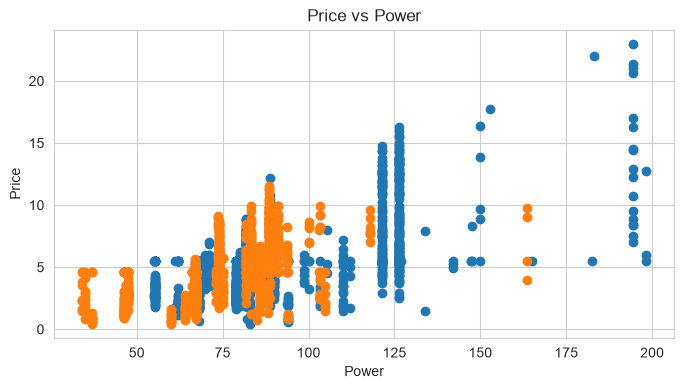

In [420]:
plt.figure(figsize=(8, 4))
plt.scatter(df.loc[df['Brand'] == 'Hyundai', 'Power'], df.loc[df['Brand'] == 'Hyundai', 'Price'])
plt.scatter(df.loc[df['Brand'] == 'Maruti', 'Power'], df.loc[df['Brand'] == 'Maruti', 'Price'])
plt.title('Price vs Power')
plt.xlabel('Power')
plt.ylabel('Price')

In [421]:
summary_diesel = df[df['Fuel_Type'] == 1].groupby('Year')['Mileage'].mean()
summary_petrol = df[df['Fuel_Type'] == 0].groupby('Year')['Mileage'].mean()

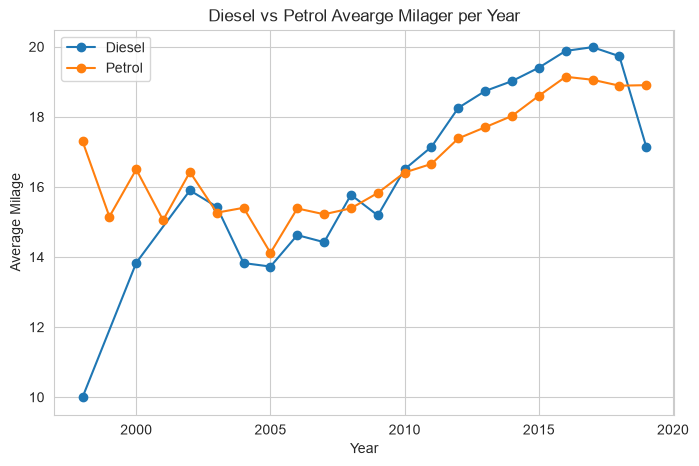

In [422]:
plt.figure(figsize=(8, 5))
plt.plot(summary_diesel.index, summary_diesel.values, marker='o', label='Diesel')
plt.plot(summary_petrol.index, summary_petrol.values, marker='o', label='Petrol')
plt.title('Diesel vs Petrol Avearge Milager per Year')
plt.xlabel('Year')
plt.ylabel('Average Milage')
plt.legend()

In [423]:
overall_summary_diesel = df[df['Fuel_Type'] == 1]['Mileage'].mean()
overall_summary_petrol = df[df['Fuel_Type'] == 0]['Mileage'].mean()

Text(0, 0.5, 'Avearge Milage')

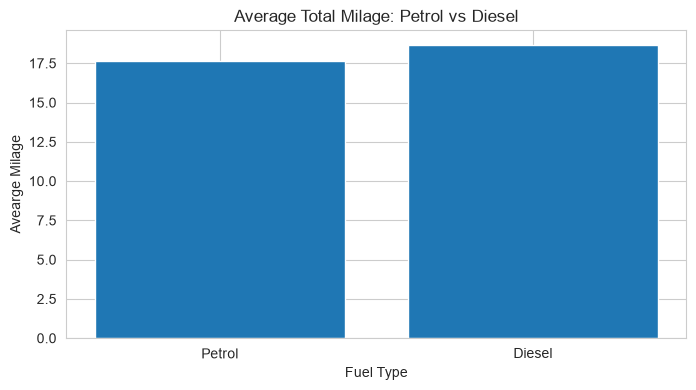

In [424]:
plt.figure(figsize=(8, 4))
plt.bar(['Petrol', 'Diesel'], [overall_summary_petrol, overall_summary_diesel])
plt.title('Average Total Milage: Petrol vs Diesel')
plt.xlabel('Fuel Type')
plt.ylabel('Avearge Milage')

Text(0.5, 1.0, 'Total Manual vs Automatic')

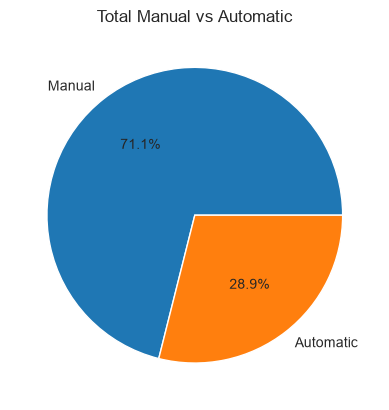

In [425]:
groups = ['Manual', 'Automatic']
counts = df['Transmission'].value_counts()

plt.pie(counts, autopct='%1.1f%%', labels=groups)
plt.title('Total Manual vs Automatic')


In [426]:
Manual_per_year = df[df['Transmission'] == 1].groupby('Year')['Transmission'].count()
Automatic_per_year = df[df['Transmission'] == 0].groupby('Year')['Transmission'].count()


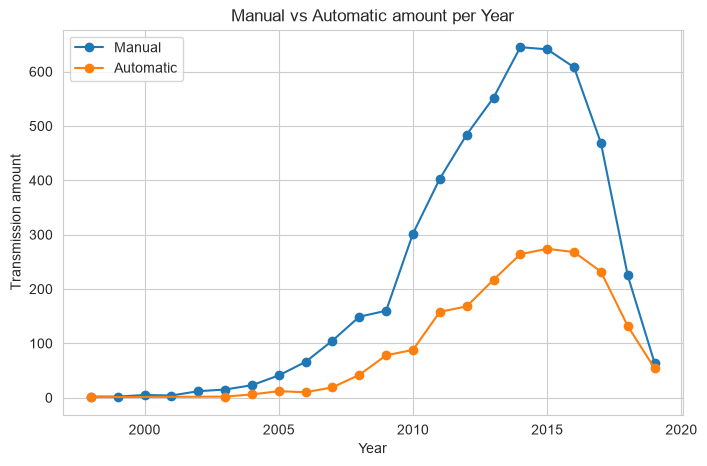

In [427]:
plt.figure(figsize=(8, 5))
plt.plot(Manual_per_year.index, Manual_per_year.values, marker='o', label='Manual')
plt.plot(Automatic_per_year.index, Automatic_per_year.values, marker='o', label='Automatic')
plt.title('Manual vs Automatic amount per Year')
plt.xlabel('Year')
plt.ylabel('Transmission amount')
plt.legend()

In [428]:
brand_prices = df.groupby('Brand')['Price'].mean().sort_values(ascending=True).index

Text(0.5, 1.0, 'Brand vs Price')

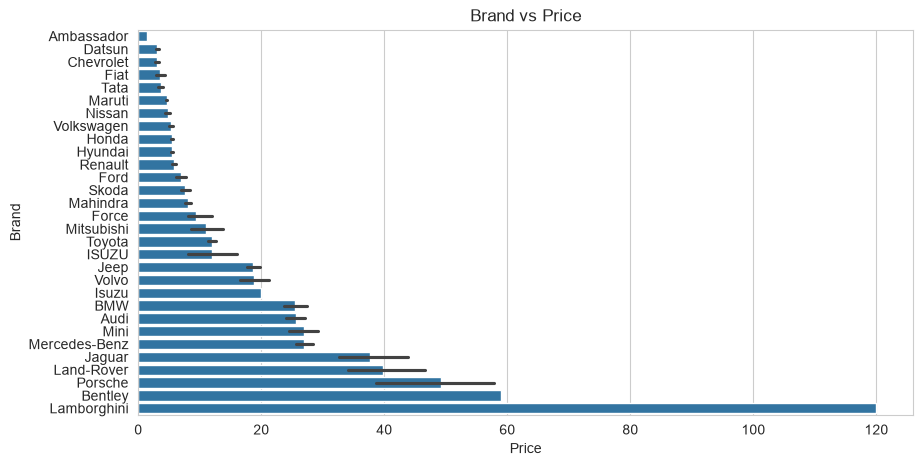

In [429]:
plt.figure(figsize=(10,5))
sns.barplot(
    x = df['Price'],
    y = df['Brand'],
    order = brand_prices
)
plt.title('Brand vs Price')

Text(0, 0.5, 'Price')

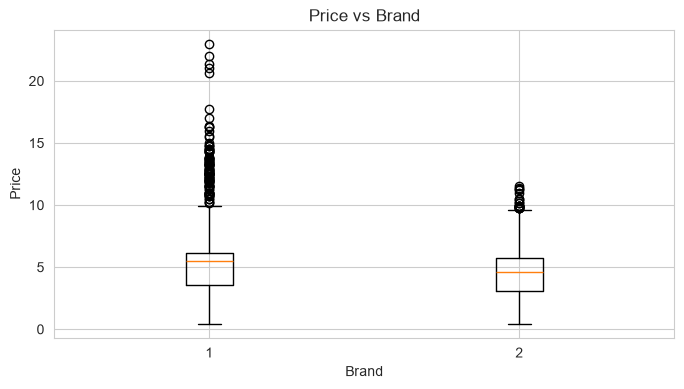

In [430]:
plt.figure(figsize=(8, 4))
plt.boxplot([df[df['Brand'] == 'Hyundai']['Price'], df[df['Brand'] == 'Maruti']['Price']])
#plt.scatter(df[df['Brand'] == 'Maruti']['Price'], df[df['Brand'] == 'Maruti']['Brand'])
plt.title('Price vs Brand')
plt.xlabel('Brand')
plt.ylabel('Price')

# Machine Learning

In [ ]:
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [432]:
df['Price'].isnull().sum()

np.int64(549)

In [433]:
df = df.dropna(subset = ['Price'])

In [434]:
df['Price'].isnull().sum()

np.int64(0)

In [466]:
X = df.iloc[:, 2:-2]
y = df['Price']

In [467]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [468]:
clf = tree.DecisionTreeRegressor()
clf = clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

In [469]:
MSE = mean_squared_error(y_test, y_pred)
R2 = r2_score(y_test, y_pred)
print('MSE:', round(MSE, 2))
print('R2:', round(R2, 4))

MSE: 33.99
R2: 0.7016


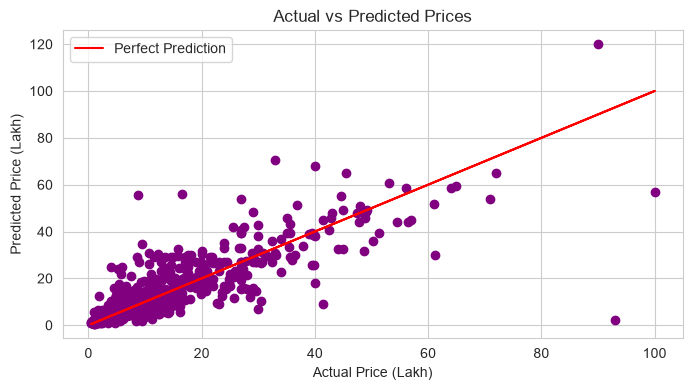

In [471]:
plt.figure(figsize=(8, 4))
plt.scatter(y_test, y_pred, color='purple')
plt.plot(y_test, y_test, color='red', label='Perfect Prediction')
plt.title('Actual vs Predicted Prices')
plt.xlabel('Actual Price (Lakh)')
plt.ylabel('Predicted Price (Lakh)')
plt.legend()
plt.grid(True)

# Explaining my machine learning model

### Model:

I chose the Decision Tree model because it is very simple to interpret and because I have a lot of numeircal columns to provide it, it can create a lot of branches and make better informed decisions.

### Performance:

It performed well giving a mean squared error of 33.99 and an R^2 score of 0.7. These a are resonalblly good with the MSE score being a little high at 33 seeming as though the mean is roughly 9 and the max is 160. However the R^2 score of 0.7 shows a pretty decent comparison of the predicted price to target price.

### Explanation:

These predictions tell us that the model was 

# RAG Chatbot

In [476]:
import numpy as np
import streamlit as st
from openai import OpenAI
from sentence_transformers import SentenceTransformer

C:\Users\hillt\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
